**Conversion Reactor: Methane Combustion**

In this tutorial we burn methane with air in an adiabatic conversion (stoichiometric) reactor, and validate the result against an equivalent DWSIM Conversion Reactor model (Peng-Robinson property package).

A conversion reactor does not use reaction kinetics or equilibrium: the user specifies how far the reaction proceeds, and the reactor applies the stoichiometry and the energy balance.

### Reaction:

$$\mathrm{CH_4 + 2\,O_2 \rightarrow CO_2 + 2\,H_2O} \qquad \Delta H_r(25\,^{\circ}\mathrm{C}) \approx -802.6\ \mathrm{kJ/mol\ CH_4}$$

* **Base component**: methane
* **Specified conversion**: 95 %
* **Reaction phase**: vapor
* **Operation**: adiabatic, no pressure drop

### Inlet Specifications:

| Stream | Composition (mol) | Mass Flow | Temperature | Pressure |
|---|---|---|---|---|
| Fuel | 100 % methane | 1 kg/s | 300 K | 1.01325 bar |
| Air | 79 % nitrogen, 21 % oxygen | 5 kg/s | 300 K | 1.01325 bar |

The fuel and air are mixed in a `Mixer` before the reactor, and the flue gas leaves through a `Product`.

---

> **Limiting reactant**
>
> 5 kg/s of air contains only 36.4 mol/s of oxygen, while burning 95 % of the 62.3 mol/s of methane would need 118.4 mol/s. The mixture is very fuel-rich, so **oxygen runs out first** and only 29.2 % of the methane burns. DWSIM silently caps the conversion at the limiting reactant; `conversion_reactor.py` does the same explicitly and reports which reactant is limiting. Complete combustion would need about 17.2 kg of air per kg of methane.

> **Heat of reaction**
>
> The property package `combustion_gas.py` includes each component's ideal gas heat of formation at 25 °C in its enthalpy, so the heat released by the reaction appears in the energy balance automatically. The reactor is therefore built with `has_heat_of_reaction=False`; adding a heat of reaction term as well would count it twice.

> **Heat capacities at flame temperature**
>
> The usual Poling heat capacity correlations are only valid up to 1000 K and are badly wrong at flame temperatures. `combustion_gas.py` fits the ideal gas heat capacities to CoolProp's reference values over 298–2000 K instead.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the flowsheet

The flowsheet is fuel and air Feeds → Mixer → StoichiometricReactor → flue gas Product, built in `conversion_reactor.py`. The extent of reaction is calculated from the specified conversion and the limiting reactant, then fixed in the reactor.

In [2]:
from conversion_reactor import setup_conversion_reactor_model, report_conversion_reactor_properties

# Create and solve the model
model, results = setup_conversion_reactor_model(
    fuel={"flow_mass": 1.0, "temperature": 300, "pressure": 101325, "mole_frac": {"methane": 1.0}},  # kg/s, K, Pa
    air={"flow_mass": 5.0, "temperature": 300, "pressure": 101325, "mole_frac": {"nitrogen": 0.79, "oxygen": 0.21}},
    conversion=0.95,  # specified methane conversion
)
print(results.solver.termination_condition)

prop = report_conversion_reactor_properties(model)

The initial DOF is 17
Limiting reactant: oxygen, extent of reaction: 18.1974 mol/s, methane conversion: 29.19%
The final DOF is 0
optimal

Unit : fs.fuel                                                             Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                                           Units        Outlet  
    Total Molar Flowrate                mole / second     62.335
    Total Mole Fraction methane         dimensionless     1.0000
    Total Mole Fraction oxygen          dimensionless 1.0000e-10
    Total Mole Fraction nitrogen        dimensionless 1.0000e-10
    Total Mole Fraction carbon_dioxide  dimensionless 1.0000e-10
    Total Mole Fraction water           dimensionless 1.0000e-10
    Temperature                                kelvin     300.00
    Pressure                                   pascal 1.0132e+05

Unit : fs.air                                                              Time: 0.0
---

In [3]:
# Visualize (if needed)
model.fs.visualize("Conversion Reactor Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-11-01 11:52:21 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-11-01 11:52:21 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'Conversion Reactor Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Conversion Reactor)
2026-11-01 11:52:21 [WARNING] idaes.idaes_ui.fv.fsvis: Flowsheet name changed: old='Conversion Reactor Model' new='Conversion-Reactor-Model'
Flowsheet name changed to 'Conversion-Reactor-Model'
2026-11-01 11:52:21 [INFO] idaes.idaes_ui.fv.fsvis: Flowsheet visualization at: http://localhost:53129/app?id=Conversion-Reactor-Model


VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x0000020CBDDCA270>, port=53129, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x0000020C81D77770>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x0000020CBDB3E9C0>>)

## DWSIM model

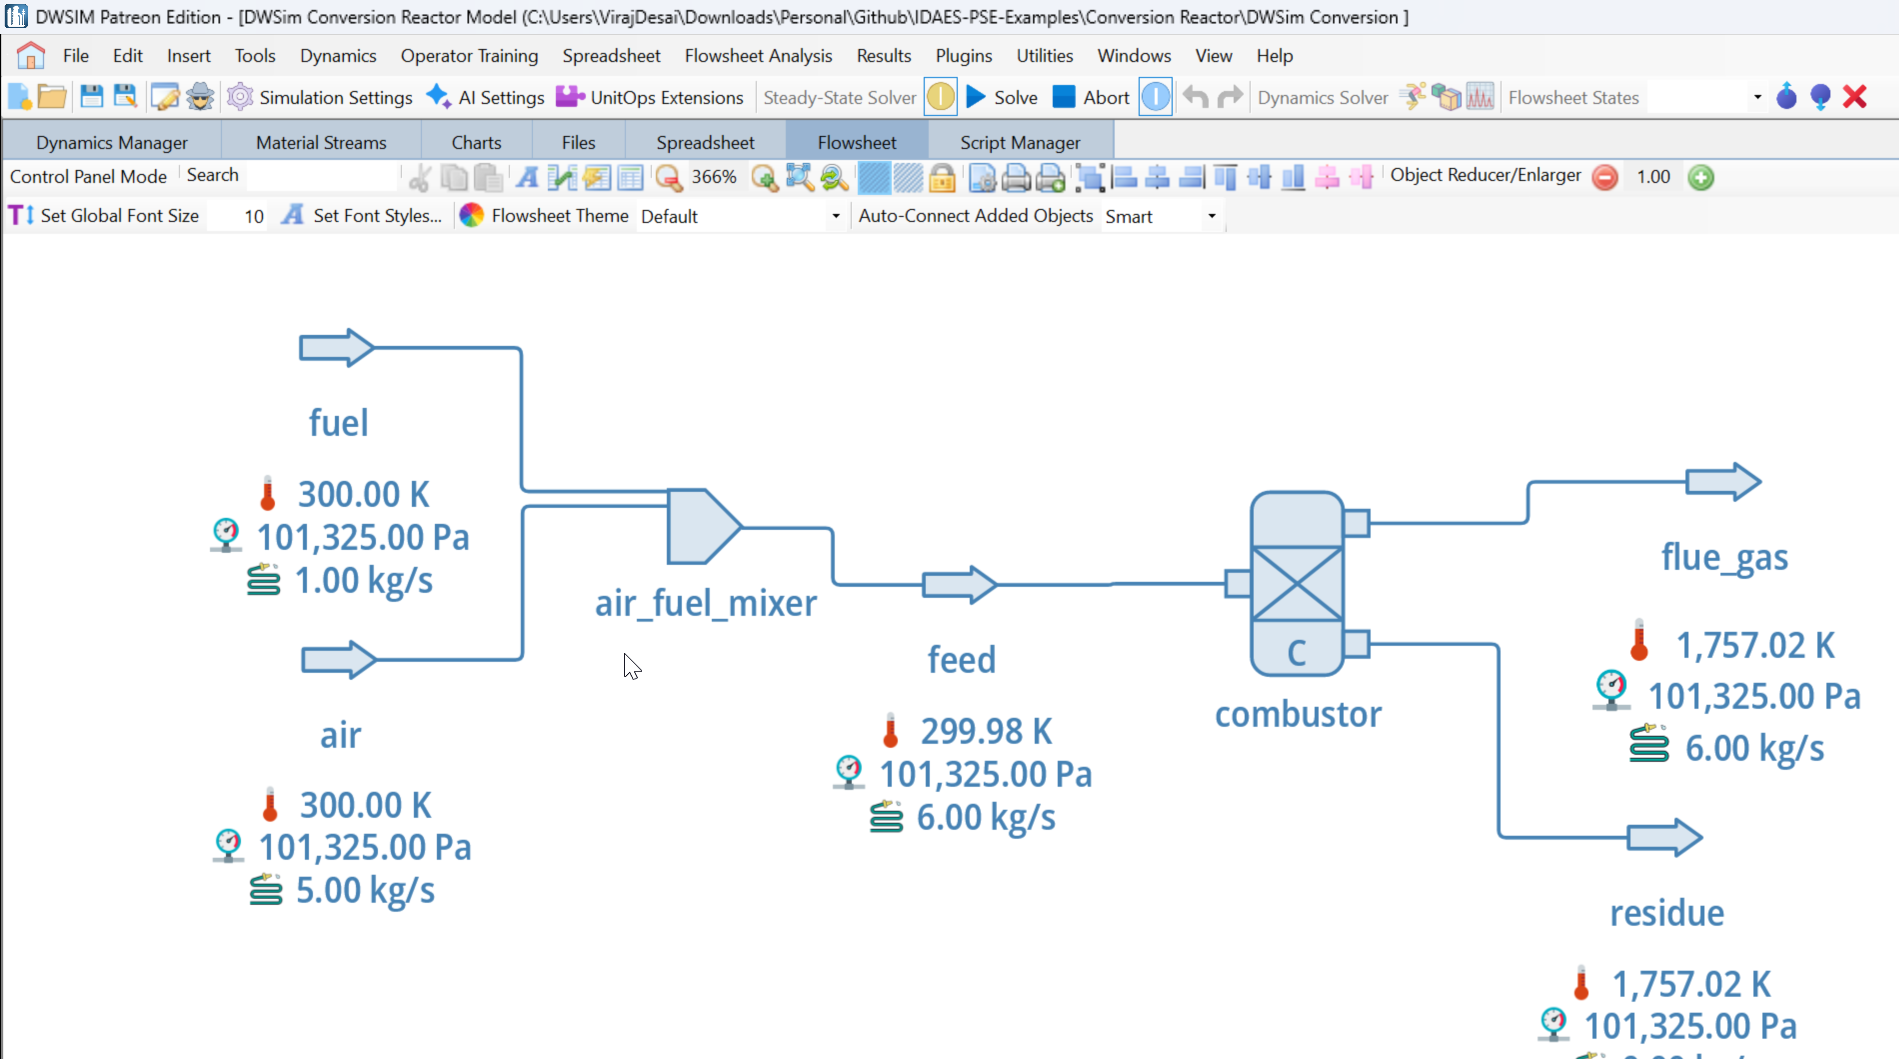

In [4]:
from IPython.display import Image
Image(filename="DWSim Conversion Reactor.png")

In [5]:
import webbrowser
import tempfile
import os

def display_image_in_browser(image_path, title="Image Viewer"):
    # Create a temporary HTML file that embeds the image
    html_content = f"""
    <html>
        <head>
            <title>{title}</title>
        </head>
        <body style="text-align: center;">
            <h2>{title}</h2>
            <img src="file://{os.path.abspath(image_path)}" style="max-width:90%; max-height:90%;">
        </body>
    </html>
    """
    with tempfile.NamedTemporaryFile('w', delete=False, suffix='.html') as f:
        f.write(html_content)
        temp_html_path = f.name

    webbrowser.open(f'file://{temp_html_path}')


In [6]:
display_image_in_browser("DWSim Conversion Reactor.png", title="DWSim Conversion Reactor Model Check")

## Validation against DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file and compared with IDAES. The flue gas flows follow from the stoichiometry and should match exactly. The flue gas temperature differs slightly because of the ideal gas heat capacity data (CoolProp fit in IDAES vs DWSIM's ChemSep database).

In [ ]:
from conversion_reactor import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results("DWSim Conversion Reactor Model.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Difference,Error (%)
Flue gas temperature (K),1.754820e+03,1.757024e+03,-2.203741e+00,-1.254247e-01
Temperature rise (K),1.454836e+03,1.457040e+03,-2.203567e+00,-1.512359e-01
Flue gas mass flow (kg/s),6.000000e+00,6.000000e+00,2.113681e-09,3.522801e-08
Flue gas molar flow (mol/s),2.356428e+02,2.356428e+02,7.692628e-08,3.264529e-08
Flue gas methane (mol/s),4.413722e+01,4.413722e+01,1.421409e-08,3.220433e-08
Flue gas oxygen (mol/s),2.929438e-15,1.421085e-14,-1.128142e-14,NaN
Flue gas nitrogen (mol/s),1.369135e+02,1.369135e+02,6.233421e-09,4.552817e-09
Flue gas carbon_dioxide (mol/s),1.819736e+01,1.819736e+01,2.668101e-08,1.466202e-07
Flue gas water (mol/s),3.639473e+01,3.639473e+01,2.979775e-08,8.187382e-08


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 60889)
Traceback (most recent call last):
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\socketserver.py", line 318, in _handle_request_noblock
    self.process_request(request, client_address)
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\socketserver.py", line 349, in process_request
    self.finish_request(request, client_address)
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\socketserver.py", line 362, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\.venv\Lib\site-packages\idaes_ui\fv\model_server.py", line 257, in __init__
    super().__init__(*args, **kwargs)
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\http\server.py", line 672, in __init__
    super().__init__(*args, *